# Атом Гелію методом Хартрі–Фока (PySCF)

**Мета роботи:**

1. Розрахувати атом He методом RHF у кількох нескладних базисних наборах.
2. Отримати молекулярні орбіталі, побудувати їхні графіки, визначити зайняті та віртуальні орбіталі.
3. Побудувати детермінант Слейтера на отриманих орбіталях.
4. Перевірити повну енергію через одноелектронні та двоелектронні інтеграли.
5. Додаткові завдання для самостійного виконання.

> Перед початком роботи переконайтесь, що встановлено пакет `pyscf`:
> ```
> pip install pyscf
> ```


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pyscf import gto, scf, ao2mo

np.set_printoptions(precision=6, suppress=True)


## Частина 1. Різні базиси для методу RHF

Атом гелію — найпростіша багатоелектронна система (2 електрони, замкнена оболонка $1s^2$).
Спробуємо декілька нескладних базисних наборів різного розміру та подивимось, як від цього
змінюється розрахована енергія RHF.

**Завдання для студентів:** додайте у список `basis_list` ще 1–2 базиси на власний розсуд
(наприклад `'3-21g'`, `'6-311g'`, `'aug-cc-pvdz'`) і подивіться, як змінюється результат.


In [2]:
basis_list = ['sto-3g', '6-31g', '6-31g**', 'cc-pvdz', 'cc-pvtz']

results = {}
for basis in basis_list:
    mol = gto.M(atom='He 0 0 0', basis=basis, spin=0, charge=0, verbose=0)
    mf = scf.RHF(mol)
    e_tot = mf.kernel()
    results[basis] = dict(mol=mol, mf=mf, e_tot=e_tot)
    print(f'{basis:10s}  nao = {mol.nao:2d}   E(RHF) = {e_tot: .8f} Hartree')


sto-3g      nao =  1   E(RHF) = -2.80778396 Hartree
6-31g       nao =  2   E(RHF) = -2.85516043 Hartree
6-31g**     nao =  5   E(RHF) = -2.85516043 Hartree
cc-pvdz     nao =  5   E(RHF) = -2.85516048 Hartree
cc-pvtz     nao = 14   E(RHF) = -2.86115334 Hartree


Для порівняння: "точна" нерелятивістська енергія основного стану атома He
(з урахуванням електронної кореляції) становить приблизно **-2.903724 Hartree**.
Різниця між цим значенням і енергією RHF — це **енергія кореляції**, яку метод
Хартрі–Фока принципово не враховує (кожен електрон рухається в усередненому полі іншого).

Побудуємо графік залежності енергії RHF від розміру базису (кількості базисних функцій):

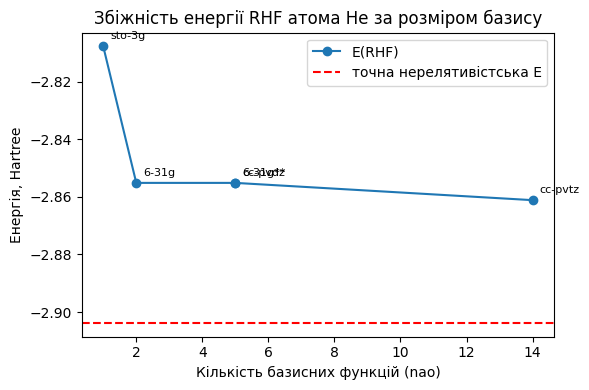

In [3]:
naos = [results[b]['mol'].nao for b in basis_list]
energies = [results[b]['e_tot'] for b in basis_list]

plt.figure(figsize=(6,4))
plt.plot(naos, energies, 'o-', label='E(RHF)')
plt.axhline(-2.903724, color='r', ls='--', label='точна нерелятивістська E')
for b, n, e in zip(basis_list, naos, energies):
    plt.annotate(b, (n, e), textcoords="offset points", xytext=(5,5), fontsize=8)
plt.xlabel('Кількість базисних функцій (nao)')
plt.ylabel('Енергія, Hartree')
plt.title('Збіжність енергії RHF атома He за розміром базису')
plt.legend()
plt.tight_layout()
plt.show()


## Частина 2. Орбіталі: розрахунок, графіки, зайняті vs віртуальні

Оберемо один із базисів — `cc-pVDZ` (5 базисних функцій: 1 функція типу *s*, ще одна *s*,
та три *p*-функції). Для атома He (2 електрони) заповненою буде лише **одна** молекулярна
орбіталь (МО), решта — **віртуальні** (незаповнені) орбіталі.


In [4]:
mol = gto.M(atom='He 0 0 0', basis='cc-pvdz', spin=0, charge=0, verbose=0)
mf = scf.RHF(mol)
e_tot = mf.kernel()

print('Повна енергія RHF:', e_tot, 'Hartree')
print()
print('Номер MO | Енергія орбіталі (Hartree) | Заповненість (mo_occ)')
for i, (eps, occ) in enumerate(zip(mf.mo_energy, mf.mo_occ)):
    tag = 'ЗАЙНЯТА' if occ > 0 else 'віртуальна'
    print(f'  MO {i}   |  {eps: .6f}                |   {occ:.1f}   -> {tag}')


Повна енергія RHF: -2.85516047724274 Hartree

Номер MO | Енергія орбіталі (Hartree) | Заповненість (mo_occ)
  MO 0   |  -0.914148                |   2.0   -> ЗАЙНЯТА
  MO 1   |   1.397442                |   0.0   -> віртуальна
  MO 2   |   2.524372                |   0.0   -> віртуальна
  MO 3   |   2.524372                |   0.0   -> віртуальна
  MO 4   |   2.524372                |   0.0   -> віртуальна


Отже, `MO 0` — єдина **зайнята** орбіталь (двічі, з протилежними спінами, $1s^2$),
а всі інші МО — **віртуальні**: вони не заповнені електронами в основному стані, але
формально є розв'язками рівняння Фока і використовуються, наприклад, для опису
збуджених станів або в пост-Хартрі–Фоківських методах (MP2, CI, CCSD...).

### Графіки орбіталей

Атом гелію сферично симетричний, тому зручно побудувати **радіальний переріз** орбіталі —
значення МО вздовж променя від ядра (вісь x), а не повну 3D-поверхню.


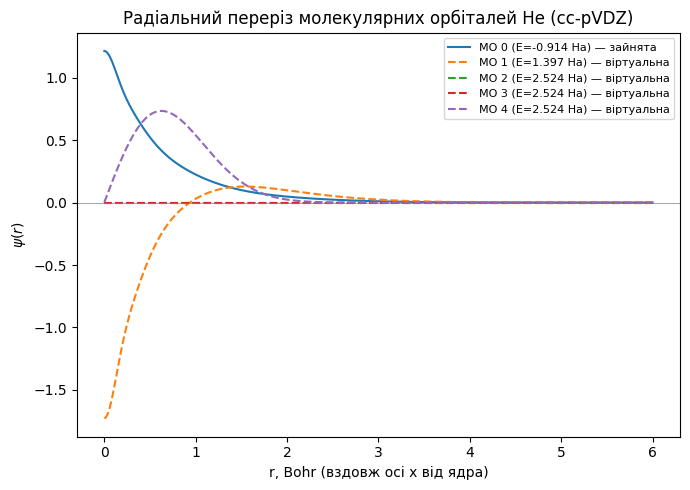

In [5]:
r = np.linspace(0.001, 6.0, 400)
coords = np.zeros((len(r), 3))
coords[:, 0] = r

ao_vals = mol.eval_gto('GTOval', coords)     # (npoints, nao) значення АО на сітці
mo_vals = ao_vals @ mf.mo_coeff              # (npoints, nmo) значення МО на сітці

plt.figure(figsize=(7,5))
for i in range(mol.nao):
    occ = mf.mo_occ[i]
    style = '-' if occ > 0 else '--'
    label = f'MO {i} (E={mf.mo_energy[i]:.3f} Ha)' + (' — зайнята' if occ>0 else ' — віртуальна')
    plt.plot(r, mo_vals[:, i], style, label=label)

plt.axhline(0, color='gray', lw=0.5)
plt.xlabel('r, Bohr (вздовж осі x від ядра)')
plt.ylabel(r'$\psi(r)$')
plt.title('Радіальний переріз молекулярних орбіталей He (cc-pVDZ)')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()


**Завдання для студентів:** побудуйте також графік радіальної густини ймовірності
зайнятої орбіталі, $4\pi r^2 |\psi_{1s}(r)|^2$ (густина ймовірності знаходження електрона
на відстані $r$ від ядра) і знайдіть, при якому $r$ вона максимальна.


## Частина 2а. Орбіталь "вручну": з коефіцієнтів базису і коефіцієнтів МО

Вище значення орбіталей на сітці отримувались функцією `mol.eval_gto(...)` — це "чорна
скринька" PySCF. Але насправді МО — це **абсолютно явна аналітична функція**, і її
легко побудувати самостійно, маючи лише два набори чисел, які вже є в нашому розрахунку:

1. **Параметри базисних функцій** (АО) — показники експонент $\alpha_k$ та контраційні
   коефіцієнти $d_k$ гаусіан, з яких складена кожна базисна функція. Це властивості
   *базисного набору*, а не результат SCF — вони прописані в базисі (`sto-3g`, `6-31g`, ...)
   і доступні через `mol.bas_exp(...)`, `mol.bas_ctr_coeff(...)`.
2. **Коефіцієнти МО** $C_{\mu i}$ — результат SCF (`mf.mo_coeff`), які показують, з якою
   вагою кожна базисна функція $\chi_\mu$ входить в молекулярну орбіталь $\varphi_i$:
$$\varphi_i(\mathbf{r}) = \sum_\mu C_{\mu i}\,\chi_\mu(\mathbf{r})$$

Кожна контрактована гаусова базисна функція (s-типу) — це сума primitives:
$$\chi_\mu(\mathbf{r}) = \sum_k d_k \, N(\alpha_k) \, e^{-\alpha_k r^2},
\qquad N(\alpha) = \left(\frac{2\alpha}{\pi}\right)^{3/4}$$
(для p-типу до кожного доданка додається множник $x$, $y$ або $z$ та інша нормувальна
константа — див. код нижче).

Нижче ми зберемо орбіталь **повністю вручну** (без жодного виклику `eval_gto`) і
переконаємось, що результат співпадає з тим, що дає PySCF.


In [6]:
def manual_ao_values(mol, coords):
    """
    Обчислює значення всіх атомних базисних функцій (АО) у наборі точок coords,
    використовуючи лише 'сирі' параметри базису (експоненти й коефіцієнти
    контракції primitives), без виклику mol.eval_gto.
    Підтримує s- та p-оболонки (цього достатньо для sto-3g/6-31g/6-31g**/cc-pvdz).
    """
    coords = np.asarray(coords)
    r2 = np.sum(coords**2, axis=1)
    ao_cols = []
    for ib in range(mol.nbas):
        l = mol.bas_angular(ib)          # орбітальне число оболонки (0=s, 1=p, ...)
        exps = mol.bas_exp(ib)           # показники експонент primitives, alpha_k
        coefs = mol.bas_ctr_coeff(ib)    # контраційні коефіцієнти d_k, форма (nprim, nctr)
        nctr = coefs.shape[1]

        for ic in range(nctr):
            if l == 0:
                # --- s-оболонка: chi(r) = sum_k d_k * N(alpha_k) * exp(-alpha_k r^2) ---
                val = np.zeros(len(coords))
                for k, alpha in enumerate(exps):
                    d = coefs[k, ic]
                    N = (2*alpha/np.pi)**0.75
                    val += d * N * np.exp(-alpha*r2)
                ao_cols.append(val)

            elif l == 1:
                # --- p-оболонка: три компоненти px, py, pz ---
                # chi_x(r) = sum_k d_k * N_p(alpha_k) * x * exp(-alpha_k r^2), аналогічно y, z
                vals_xyz = [np.zeros(len(coords)) for _ in range(3)]
                for k, alpha in enumerate(exps):
                    d = coefs[k, ic]
                    N = (2*alpha/np.pi)**0.75 * np.sqrt(4*alpha)
                    expo = np.exp(-alpha*r2)
                    for comp in range(3):
                        vals_xyz[comp] += d * N * coords[:, comp] * expo
                ao_cols.extend(vals_xyz)   # порядок px, py, pz -- такий самий, як у PySCF
            else:
                raise NotImplementedError('У цьому прикладі підтримані лише s- та p-оболонки')

    return np.array(ao_cols).T   # форма (npoints, nao)


# --- перевірка: порівняємо з mol.eval_gto на випадкових точках ---
np.random.seed(0)
test_pts = np.random.uniform(-2, 2, size=(6, 3))

ao_manual = manual_ao_values(mol, test_pts)
ao_pyscf = mol.eval_gto('GTOval', test_pts)

print('Максимальне розходження АО (ручний розрахунок vs mol.eval_gto):')
print(np.max(np.abs(ao_manual - ao_pyscf)))


Максимальне розходження АО (ручний розрахунок vs mol.eval_gto):
2.220446049250313e-16


Розходження — на рівні машинної точності (~$10^{-15}$), тобто наша "ручна" функція
дає **точно ті самі** значення АО, що й вбудована функція PySCF.

Тепер побудуємо МО (зайняту орбіталь `MO 0`) на радіальній сітці повністю вручну —
через $\varphi_1(\mathbf{r}) = \sum_\mu C_{\mu,0}\,\chi_\mu(\mathbf{r})$ — і накладемо
на графік, отриманий раніше через `eval_gto`, щоб візуально переконатись у збігу.


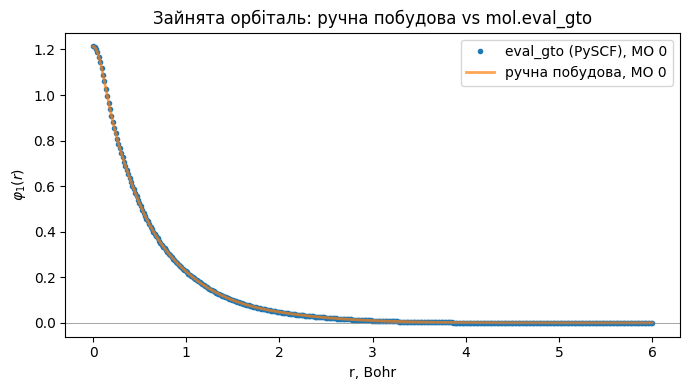

Максимальне розходження MO (ручна vs eval_gto): 4.440892098500626e-16


In [7]:
occ_idx = 0   # індекс зайнятої просторової орбіталі (MO 0), знадобиться і далі

ao_manual_grid = manual_ao_values(mol, coords)      # coords -- та сама радіальна сітка, що й вище
mo_manual_grid = ao_manual_grid @ mf.mo_coeff        # phi_i(r) = sum_mu C_{mu,i} * chi_mu(r)

plt.figure(figsize=(7,4))
plt.plot(r, mo_vals[:, occ_idx], 'o', ms=3, label='eval_gto (PySCF), MO 0')
plt.plot(r, mo_manual_grid[:, occ_idx], '-', lw=2, alpha=0.7, label='ручна побудова, MO 0')
plt.axhline(0, color='gray', lw=0.5)
plt.xlabel('r, Bohr')
plt.ylabel(r'$\varphi_1(r)$')
plt.title('Зайнята орбіталь: ручна побудова vs mol.eval_gto')
plt.legend()
plt.tight_layout()
plt.show()

print('Максимальне розходження MO (ручна vs eval_gto):',
      np.max(np.abs(mo_manual_grid - mo_vals)))


Отже, **так** — і АО, і МО можна повністю побудувати самостійно, знаючи лише:
експоненти й коефіцієнти контракції базисних гаусіан (властивості обраного базисного
набору, наприклад `6-31g` чи `cc-pvdz`) та коефіцієнти $C_{\mu i}$, які повертає SCF-розрахунок.
`mol.eval_gto` — це просто швидка (написана на C) реалізація тієї самої формули,
яку ми щойно відтворили в Python.


## Частина 3. Детермінант Слейтера

Хвильова функція RHF для замкненої оболонки — це **один детермінант Слейтера**,
побудований зі спін-орбіталей. Для атома He з єдиною просторовою орбіталлю $\varphi_1(\mathbf{r})$,
заповненою двома електронами з протилежними спінами, спін-орбіталі:

$$\chi_1(\mathbf{x}) = \varphi_1(\mathbf{r})\,\alpha(\omega), \qquad
  \chi_2(\mathbf{x}) = \varphi_1(\mathbf{r})\,\beta(\omega)$$

де $\mathbf{x} = (\mathbf{r}, \omega)$ включає просторові та спінові координати.

Детермінант Слейтера:

$$
\Psi(\mathbf{x}_1, \mathbf{x}_2) = \frac{1}{\sqrt{2}}
\begin{vmatrix}
\chi_1(\mathbf{x}_1) & \chi_2(\mathbf{x}_1) \\
\chi_1(\mathbf{x}_2) & \chi_2(\mathbf{x}_2)
\end{vmatrix}
= \frac{1}{\sqrt{2}}\Big[\chi_1(\mathbf{x}_1)\chi_2(\mathbf{x}_2) - \chi_2(\mathbf{x}_1)\chi_1(\mathbf{x}_2)\Big]
$$

Підставляючи явний вигляд спін-орбіталей, просторова частина виноситься за дужки
(оскільки просторова орбіталь для обох електронів однакова), і залишається добуток
просторової та спінової частин:

$$
\Psi(\mathbf{x}_1, \mathbf{x}_2) = \varphi_1(\mathbf{r}_1)\,\varphi_1(\mathbf{r}_2)\;
\frac{1}{\sqrt{2}}\Big[\alpha(1)\beta(2) - \beta(1)\alpha(2)\Big]
$$

Це саме той антисиметричний **синглетний** спіновий стан, який відповідає замкненій
оболонці $1s^2$: просторова частина симетрична, спінова — антисиметрична, тому повна
хвильова функція антисиметрична (як і має бути для ферміонів).

Нижче — числова реалізація детермінанта Слейтера через МО, отримані з нашого RHF-розрахунку.


In [8]:
# occ_idx вже визначено вище (= 0, єдина зайнята орбіталь He)

def phi1(r_vec):
    """Значення зайнятої просторової MO у точці r_vec = (x,y,z)."""
    coord = np.array(r_vec).reshape(1, 3)
    ao = mol.eval_gto('GTOval', coord)
    mo = ao @ mf.mo_coeff
    return mo[0, occ_idx]

def alpha(s):
    return 1.0 if s == 'up' else 0.0

def beta(s):
    return 1.0 if s == 'down' else 0.0

def slater_He(r1, s1, r2, s2):
    """
    Значення детермінанта Слейтера Psi(x1, x2) для He,
    x_i = (r_i, s_i), s_i in {'up','down'}.
    """
    chi1_1 = phi1(r1) * alpha(s1)
    chi2_1 = phi1(r1) * beta(s1)
    chi1_2 = phi1(r2) * alpha(s2)
    chi2_2 = phi1(r2) * beta(s2)
    det = chi1_1 * chi2_2 - chi2_1 * chi1_2
    return det / np.sqrt(2.0)

# приклад: електрон 1 у точці (0.3,0,0) зі спіном up,
#          електрон 2 у точці (0.6,0,0) зі спіном down
r1, r2 = (0.3, 0.0, 0.0), (0.6, 0.0, 0.0)
val_ud = slater_He(r1, 'up', r2, 'down')
val_du = slater_He(r2, 'down', r1, 'up')   # переставили електрони місцями (1<->2)
print('Psi(1_up@r1, 2_down@r2)      =', val_ud)
print('Psi(1_down@r2, 2_up@r1)      =', -val_du, ' (має збігатись з попереднім)')

# перевірка антисиметрії: переставимо саме електрони (обидва x1<->x2)
val_swapped = slater_He(r2, 'down', r1, 'up')
print('\nПеревірка антисиметрії Psi(x1,x2) = -Psi(x2,x1):')
print('Psi(x1,x2) =', val_ud)
print('Psi(x2,x1) =', val_swapped)
print('сума (має бути ~0):', val_ud + val_swapped)

# перевірка: однаковий спін -> детермінант = 0 (принцип Паулі)
val_same_spin = slater_He(r1, 'up', r2, 'up')
print('\nОбидва електрони зі спіном up (порушення Паулі при r1=r2):')
print('Psi при r1 != r2, спіни однакові =', val_same_spin, ' (не нуль — це нормально, якщо r1!=r2)')
same_point = slater_He(r1, 'up', r1, 'up')
print('Psi при r1 == r2, спіни однакові =', same_point, ' (МАЄ бути 0 — принцип Паулі)')


Psi(1_up@r1, 2_down@r2)      = 0.23054219497878348
Psi(1_down@r2, 2_up@r1)      = 0.23054219497878348  (має збігатись з попереднім)

Перевірка антисиметрії Psi(x1,x2) = -Psi(x2,x1):
Psi(x1,x2) = 0.23054219497878348
Psi(x2,x1) = -0.23054219497878348
сума (має бути ~0): 0.0

Обидва електрони зі спіном up (порушення Паулі при r1=r2):
Psi при r1 != r2, спіни однакові = 0.0  (не нуль — це нормально, якщо r1!=r2)
Psi при r1 == r2, спіни однакові = 0.0  (МАЄ бути 0 — принцип Паулі)


Зверніть увагу: коли обидва електрони мають **однаковий спін і однакові координати**,
детермінант обертається в нуль — це прямий наслідок принципу Паулі, закладеного
в антисиметричну структуру детермінанта Слейтера.


## Частина 4. Перевірка енергії через одно- та двоелектронні інтеграли

Для замкненої оболонки з **однією** двічі зайнятою просторовою орбіталлю $\varphi_1$
повна електронна енергія RHF виражається через:

- одноелектронний інтеграл (кінетична енергія + притягання до ядра):
$$h_{11} = \int \varphi_1(\mathbf{r})\Big[-\tfrac12\nabla^2 - \tfrac{Z}{r}\Big]\varphi_1(\mathbf{r})\,d\mathbf{r}$$

- двоелектронний кулонівський інтеграл:
$$J_{11} = \iint \varphi_1(\mathbf{r}_1)^2\,\frac{1}{r_{12}}\,\varphi_1(\mathbf{r}_2)^2\,d\mathbf{r}_1 d\mathbf{r}_2$$

Тоді:
$$E_{elec} = 2h_{11} + J_{11}, \qquad E_{tot} = E_{elec} + E_{nuc}$$

(для одного атома $E_{nuc}=0$, оскільки немає інших ядер).

Отримаємо ці величини безпосередньо з інтегралів PySCF і порівняємо з `mf.e_tot`.


In [9]:
C = mf.mo_coeff

# одноелектронний гамільтоніан (hcore) в АО-базисі -> переносимо в МО-базис
hcore_ao = mf.get_hcore()
h_mo = C.T @ hcore_ao @ C
h11 = h_mo[occ_idx, occ_idx]

# двоелектронні інтеграли (ERI) в АО-базисі -> переносимо в МО-базис
eri_ao = mol.intor('int2e')
eri_mo = ao2mo.kernel(eri_ao, C)
eri_mo_full = ao2mo.restore(1, eri_mo, mol.nao)  # повний 4-індексний тензор (pq|rs)
J11 = eri_mo_full[occ_idx, occ_idx, occ_idx, occ_idx]   # (11|11)

E_elec_manual = 2*h11 + J11
E_nuc = mol.energy_nuc()
E_manual = E_elec_manual + E_nuc

print(f'h11 (одноелектронний інтеграл)        = {h11: .8f} Hartree')
print(f'J11 (кулонівський двоелектронний)      = {J11: .8f} Hartree')
print(f'E_elec = 2*h11 + J11                   = {E_elec_manual: .8f} Hartree')
print(f'E_nuc                                  = {E_nuc: .8f} Hartree')
print(f'E_tot (вручну, через інтеграли)        = {E_manual: .8f} Hartree')
print(f'E_tot (з mf.e_tot, з kernel RHF)        = {mf.e_tot: .8f} Hartree')
print(f'Різниця                                = {abs(E_manual-mf.e_tot):.2e} Hartree')


h11 (одноелектронний інтеграл)        = -1.94101255 Hartree
J11 (кулонівський двоелектронний)      =  1.02686463 Hartree
E_elec = 2*h11 + J11                   = -2.85516048 Hartree
E_nuc                                  =  0.00000000 Hartree
E_tot (вручну, через інтеграли)        = -2.85516048 Hartree
E_tot (з mf.e_tot, з kernel RHF)        = -2.85516048 Hartree
Різниця                                = 0.00e+00 Hartree


Значення повинні збігатись з точністю до похибки округлення (~$10^{-12}$–$10^{-15}$),
що підтверджує коректність побудови хвильової функції та формули енергії для
замкненооболонкового RHF.

**Завдання для студентів:** повторіть цю перевірку для базису `sto-3g` та `6-31g**`
і переконайтесь, що збіжність зберігається для будь-якого базису.


## Частина 5. Що ще можна зробити? (додаткові завдання)

Нижче наведено кілька ідей для розширення роботи — деякі із зразками коду,
деякі — як самостійні завдання.

### 5.1. Теорема Купманса — потенціал іонізації
Енергія найвищої зайнятої орбіталі (HOMO), взята зі знаком «мінус», наближено дає
перший потенціал іонізації (експериментальне значення для He: **24.59 еВ**).


In [10]:
HARTREE_TO_EV = 27.211386

ip_koopmans_ha = -mf.mo_energy[occ_idx]
ip_koopmans_ev = ip_koopmans_ha * HARTREE_TO_EV
print(f'IP (теорема Купманса) = {ip_koopmans_ha:.4f} Hartree = {ip_koopmans_ev:.2f} еВ')
print('Експериментальне значення IP(He) = 24.59 еВ')


IP (теорема Купманса) = 0.9141 Hartree = 24.88 еВ
Експериментальне значення IP(He) = 24.59 еВ


**Завдання:** порахуйте IP також "напряму" — як різницю енергій $E(\mathrm{He}^+) - E(\mathrm{He})$
(потрібно порахувати `scf.UHF` для іона He⁺, `charge=1, spin=1`) і порівняйте з обома
попередніми оцінками.

### 5.2. Теорема віріала
Для точної хвильової функції в кулонівській системі має виконуватись
$-\langle V\rangle / \langle T\rangle = 2$. Перевірте, наскільки добре це виконується
для нашого RHF-розв'язку (підказка: `mf.scf_summary` або окремо обчисліть
кінетичну й потенціальну енергію через `mol.intor('int1e_kin')` і залишок).

### 5.3. Радіальна густина ймовірності
Побудуйте графік $4\pi r^2 |\varphi_1(r)|^2$ — імовірність знайти електрон
у сферичному шарі радіуса $r$ — і знайдіть найімовірнішу відстань електрона від ядра.

### 5.4. Збіжність до базисного ліміту
Розширте таблицю з Частини 1, додавши `aug-cc-pvdz`, `cc-pvtz`, `cc-pvqz`, і побудуйте
графік $E(\mathrm{RHF})$ у функції $1/n_{ao}$ (чи іншої міри розміру базису), щоб
оцінити екстраполяцію до повного базисного набору (CBS-ліміт).

### 5.5. Візуалізація орбіталей у 3D (cube-файли)
Для «справжньої» 3D-візуалізації орбіталей (наприклад, у програмах VMD, Avogadro,
Jmol) можна експортувати орбіталь у `.cube`-файл:
```python
from pyscf.tools import cubegen
cubegen.orbital(mol, 'he_1s.cube', mf.mo_coeff[:, 0])
```

### 5.6. Іон He⁻ (штучне заповнення віртуальної орбіталі)
Що станеться з енергією, якщо штучно "заповнити" віртуальну орбіталь (не фізичний
стан, а навчальна вправа)? Порівняйте з енергією нейтрального атома і обговоріть,
чому He не утворює стабільного аніона.

### 5.7. Залежність від заряду ядра Z (ізоелектронний ряд)
Порахуйте RHF для ізоелектронного ряду H⁻, He, Li⁺, Be²⁺ (2 електрони, різний заряд
ядра) і подивіться, як змінюється енергія та розмір (радіус) орбіталі 1s.
